In [1]:
import numpy as np
import pandas as pd
from keras.preprocessing.image import ImageDataGenerator,load_img
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import random
import os
import glob
from google.colab import drive
from google.colab.patches import cv2_imshow
import cv2
from numpy import asarray
import tensorflow as tf
from keras.preprocessing.image import img_to_array
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from skimage import feature
from tensorflow.keras.losses import sparse_categorical_crossentropy
from tensorflow.keras.losses import CategoricalCrossentropy
from scipy import ndimage
import skimage.util as util
from skimage.exposure import rescale_intensity
import random as rng
import imutils
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier


In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import MaxPooling2D
from keras.layers import Dense
from keras.layers import Flatten
from keras.optimizers import SGD

In [ ]:
Image_Width=128
Image_Height=128
Image_Size=(Image_Width,Image_Height)
Image_Channels=3

In [ ]:
dir_path = '/content/drive/MyDrive/'

In [ ]:
drive.mount('/content/drive') 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data = []
resistor = 1
label = []

In [ ]:
img_file_path = dir_path + 'resistor/*.jpg'
for dog_file in glob.glob(img_file_path):
    label.append(resistor)
    image = cv2.imread(dog_file)
    image = cv2.resize(image, (200,200))   #Image is resized 
    data.append(image)
not_resistor = 0
img_file_path = dir_path + 'Not resistor/*.jpg'
for dog_file in glob.glob(img_file_path):
    label.append(not_resistor)
    image = cv2.imread(dog_file)
    image = cv2.resize(image, (200,200))
    data.append(image)
# convert to a numpy arrays
data = asarray(data)
data = data/255
label = asarray(label)

In [ ]:
model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(200,200,3)))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(10, activation='softmax'))

# Compile the model
model.compile(loss=sparse_categorical_crossentropy,
              optimizer=Adam(),
              metrics=['accuracy'])


In [ ]:
model.summary()

Model: "sequential_5"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_10 (Conv2D)           (None, 198, 198, 32)      896       
_________________________________________________________________
max_pooling2d_10 (MaxPooling (None, 99, 99, 32)        0         
_________________________________________________________________
dropout_10 (Dropout)         (None, 99, 99, 32)        0         
_________________________________________________________________
conv2d_11 (Conv2D)           (None, 97, 97, 64)        18496     
_________________________________________________________________
max_pooling2d_11 (MaxPooling (None, 48, 48, 64)        0         
_________________________________________________________________
dropout_11 (Dropout)         (None, 48, 48, 64)        0         
_________________________________________________________________
flatten_5 (Flatten)          (None, 147456)           

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data, label, test_size=0.33, random_state=42) # split the data into train and test datak,

In [ ]:
history = model.fit(data, label, epochs=10,validation_split = 0.1)

Epoch 1/10
3/3 [==============================] - 7s 2s/step - loss: 8.5495 - accuracy: 0.1999 - val_loss: 0.1394 - val_accuracy: 1.0000
Epoch 2/10
3/3 [==============================] - 8s 3s/step - loss: 3.4982 - accuracy: 0.5457 - val_loss: 4.3778 - val_accuracy: 0.0000e+00
Epoch 3/10
3/3 [==============================] - 8s 2s/step - loss: 3.2720 - accuracy: 0.5847 - val_loss: 0.6584 - val_accuracy: 1.0000
Epoch 4/10
3/3 [==============================] - 6s 2s/step - loss: 1.2877 - accuracy: 0.4660 - val_loss: 1.0924 - val_accuracy: 1.0000
Epoch 5/10
3/3 [==============================] - 5s 1s/step - loss: 0.7775 - accuracy: 0.5167 - val_loss: 1.7229 - val_accuracy: 0.5000
Epoch 6/10
3/3 [==============================] - 5s 1s/step - loss: 0.6872 - accuracy: 0.6888 - val_loss: 1.5741 - val_accuracy: 0.3000
Epoch 7/10
3/3 [==============================] - 5s 1s/step - loss: 0.6155 - accuracy: 0.6699 - val_loss: 1.0725 - val_accuracy: 0.4000
Epoch 8/10
3/3 [=====================

In [ ]:
y_pred = new_model.predict(X_test) # predict using the test data
# Generate arg maxes for predictions
y_pred = np.argmax(y_pred, axis = 1)
accuracy_score(y_test, y_pred) #Accuracy of the model

0.8709677419354839

In [ ]:
precision_score(y_test, y_pred, average='micro')


0.8709677419354839

In [ ]:

l = []

image = cv2.imread('/content/001.jpg')
image = cv2.resize(image, (200,200))
l.append(image)
l= asarray(l)
prediction = new_model.predict(l)
# Generate arg maxes for predictions
classes = np.argmax(prediction, axis = 1)
print(classes)
if classes == 1:
   print("resistor detected")
else:
   print("resistor not detected")

[1]
resistor detected


In [ ]:
# Save the entire model as a SavedModel.
#!mkdir -p saved_model
#model.save(dir_path + 'saved_model/my_model')

In [ ]:
new_model = tf.keras.models.load_model('/content/drive/MyDrive/saved_model/my_model')

In [ ]:
prediction = new_model.predict(l)
# Generate arg maxes for predictions
classes = np.argmax(prediction, axis = 1)
print(classes)
if classes == 1:
   print("resistor detected")
else:
   print("resistor not detected")

[1]
resistor detected


In [ ]:
y_pred.shape

(31, 10)

In [ ]:
#model.save('my_model_1.h5')

Contour Detection

In [ ]:
import cv2
import numpy as np
img_file_path = dir_path + 'resistor/*.jpg' 
for resistor in glob.glob(img_file_path):#read data from google drive
  # Let's load a simple image with 3 black squares
  image = cv2.imread(resistor)

  cv2.waitKey(0)

  # Grayscale
  gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

  # Find Canny edges
  edged = cv2.Canny(image, 260, 400)
  cv2.waitKey(0)

  # Finding Contours
  # Use a copy of the image e.g. edged.copy()
  # since findContours alters the image
  contours, hierarchy = cv2.findContours(edged, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

  cv2_imshow(edged)
  cv2.waitKey(0)

  print("Number of Contours found = " + str(len(contours)))

  # Draw all contours
  # -1 signifies drawing all contours
  cv2.drawContours(image, contours, -1, (0, 255, 0), 3)

  cv2_imshow(image)
  cv2.waitKey(0)
  cv2.destroyAllWindows()
  


In [ ]:
contours = np.array(contours)

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:1: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  """Entry point for launching an IPython kernel.


Band Recognition

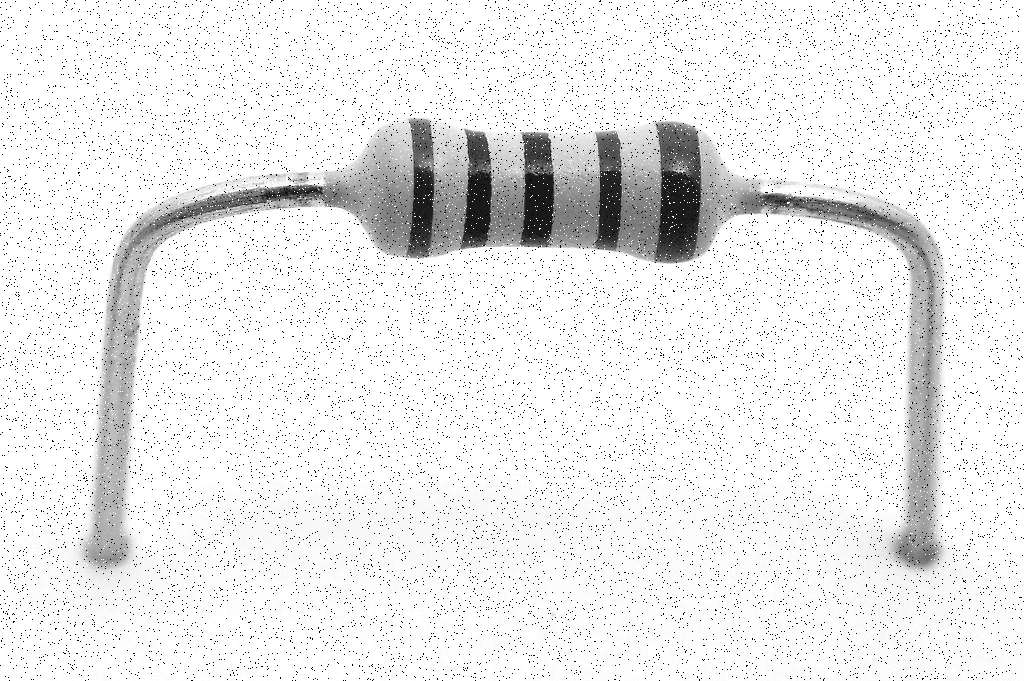

In [15]:
#  read image and convert to greyscale
rose = cv2.imread('/content/res2.jpg')
grey = cv2.cvtColor(rose, cv2.COLOR_RGB2GRAY)

#  add salt and pepper noise
grey_sp = util.random_noise(grey, 's&p', clip=True)

#  results returned was scaled between 0 and 1. Change it to 0 and 255
grey_sp = (grey_sp*255).astype(np.uint8)

#  add Gaussian noise
grey_gauss = util.random_noise(grey, 'gaussian', clip=True)

grey_gauss = (grey_gauss*255).astype(np.uint8)
cv2_imshow(grey_sp)

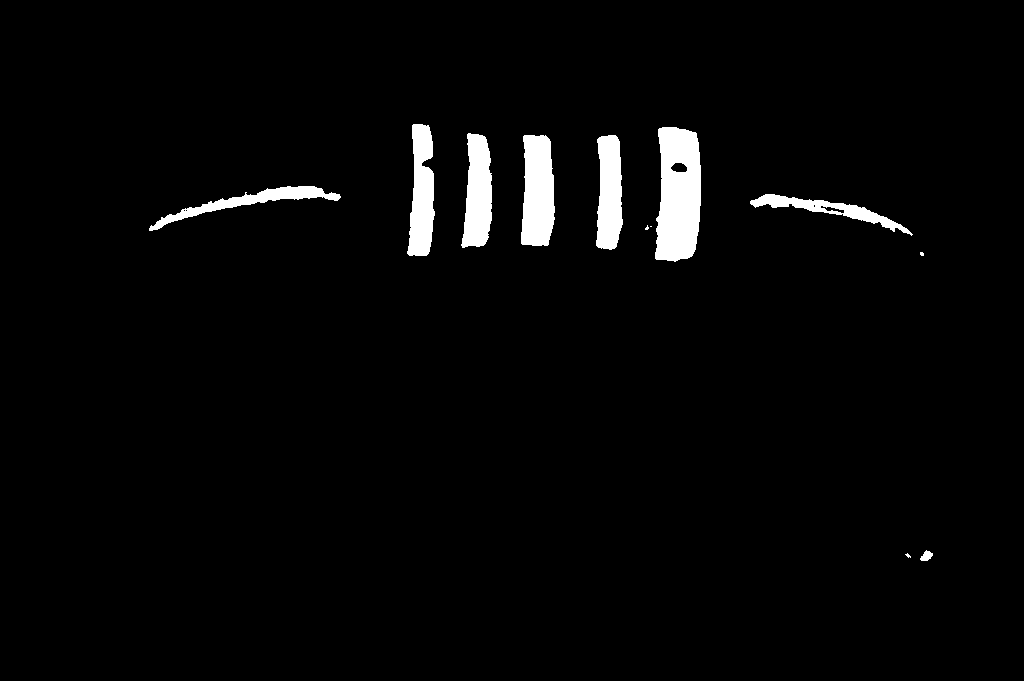

In [16]:
# use a median filter to denoise s&p noise
med_denoised = ndimage.median_filter(grey_sp, 5)
thresh1, bw3 = cv2.threshold(med_denoised, thresh=120, maxval=255, type=cv2.THRESH_BINARY_INV) # manually selected threshold, low values to 255
cv2_imshow(bw3)

Number of Contours found = 12


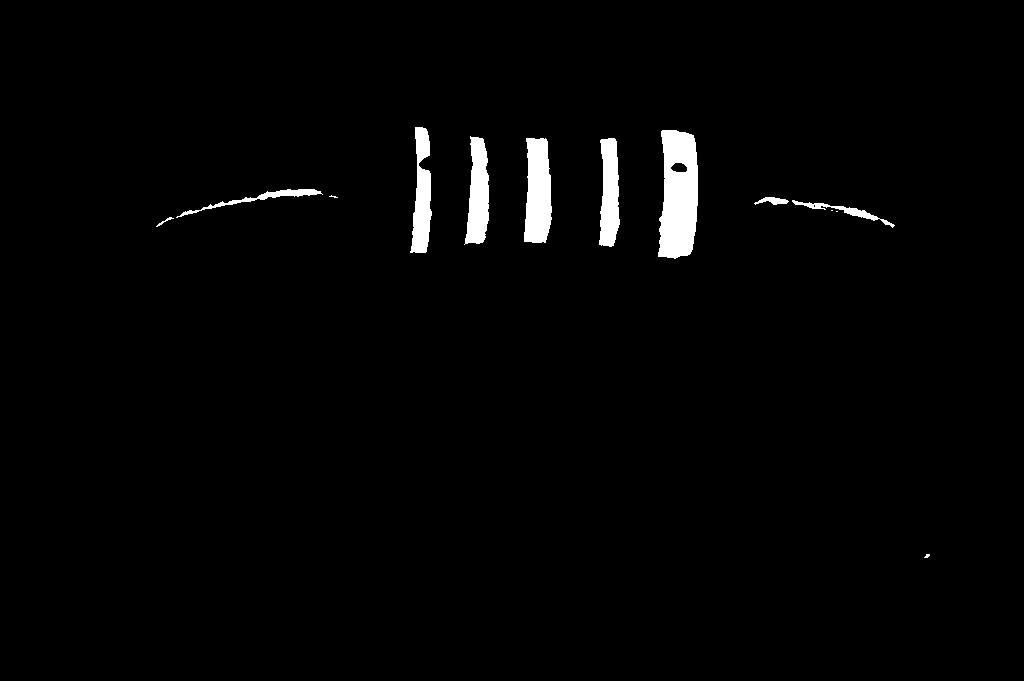

In [17]:
  # Finding Contours
  # Use a copy of the image e.g. edged.copy()
  # since findContours alters the image
contours, hierarchy = cv2.findContours(bw3, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
print("Number of Contours found = " + str(len(contours)))

  # Draw all contours
  # -1 signifies drawing all contours
cv2.drawContours(bw3, contours, -1, (0, 255, 0), 3)
cv2_imshow(bw3)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [18]:
rng.seed(12345)
drawing = np.zeros((681, 1024, 3), dtype=np.uint8)
def thresh_callback(val):
    threshold = val
    
    canny_output = cv2.Canny(bw3, threshold, threshold * 2)
    
    
    contours, hierachy = cv2.findContours(canny_output, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    
    
    contours_poly = [None]*len(contours)
    boundRect = [None]*len(contours)
    centers = [None]*len(contours)
    radius = [None]*len(contours)
    for i, c in enumerate(contours):
        contours_poly[i] = cv2.approxPolyDP(c, 3, True)
        boundRect[i] = cv2.boundingRect(contours_poly[i])
        centers[i], radius[i] = cv2.minEnclosingCircle(contours_poly[i])
    
    
    drawing = np.zeros((canny_output.shape[0], canny_output.shape[1], 3), dtype=np.uint8)
    
    for i in range(len(contours)):
        color = (rng.randint(0,256), rng.randint(0,256), rng.randint(0,256))
        cv2.drawContours(drawing, contours_poly, i, color)
        cv2.rectangle(drawing, (int(boundRect[i][0]), int(boundRect[i][1])), \
          (int(boundRect[i][0]+boundRect[i][2]), int(boundRect[i][1]+boundRect[i][3])), color, 2)
        #cv2.circle(drawing, (int(centers[i][0]), int(centers[i][1])), int(radius[i]), color, 2)
    
    
    canny_output = cv2.Canny(drawing, threshold, threshold * 2)
    
    
    contours, hierachy = cv2.findContours(canny_output, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    
    
    contours_poly = [None]*len(contours)
    boundRect = [None]*len(contours)
    centers = [None]*len(contours)
    radius = [None]*len(contours)
    for i, c in enumerate(contours):
        contours_poly[i] = cv2.approxPolyDP(c, 3, True)
        boundRect[i] = cv2.boundingRect(contours_poly[i])
        centers[i], radius[i] = cv2.minEnclosingCircle(contours_poly[i])
    
    
    drawing = np.zeros((canny_output.shape[0], canny_output.shape[1], 3), dtype=np.uint8)
  
    
    for i in range(len(contours)):
        color = (rng.randint(0,256), rng.randint(0,256), rng.randint(0,256))
        cv2.drawContours(drawing, contours_poly, i, color)
        cv2.rectangle(drawing, (int(boundRect[i][0]), int(boundRect[i][1])), \
          (int(boundRect[i][0]+boundRect[i][2]), int(boundRect[i][1]+boundRect[i][3])), color, 2)
       # cv2.circle(drawing, (int(centers[i][0]), int(centers[i][1])), int(radius[i]), color, 2)
       
    cv2_imshow(drawing)
    

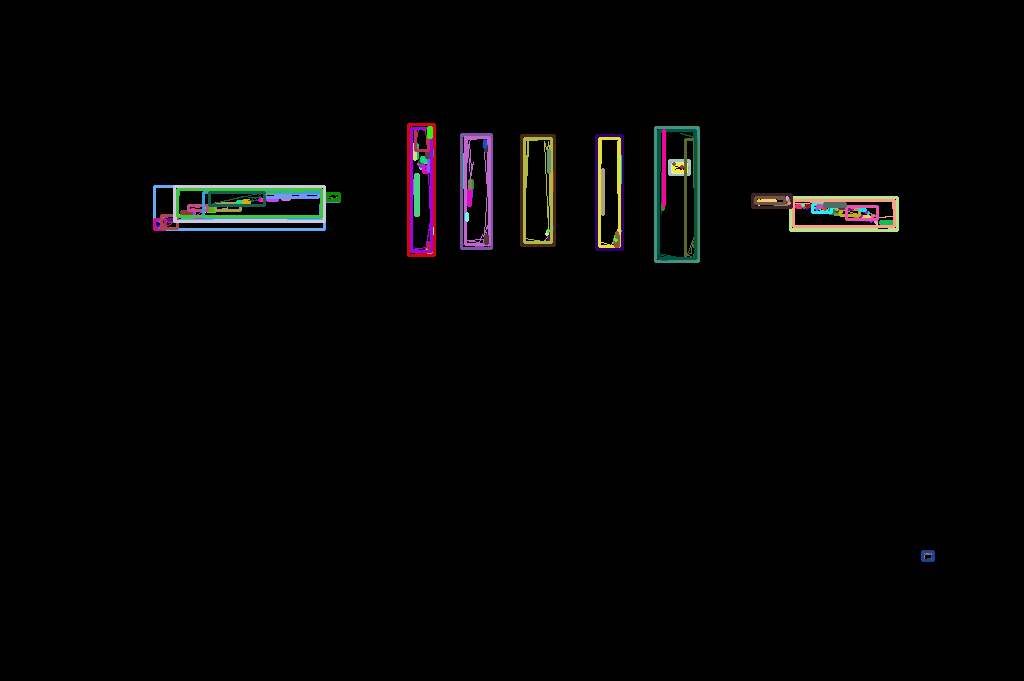

In [19]:
thresh = 100
thresh_callback(thresh)

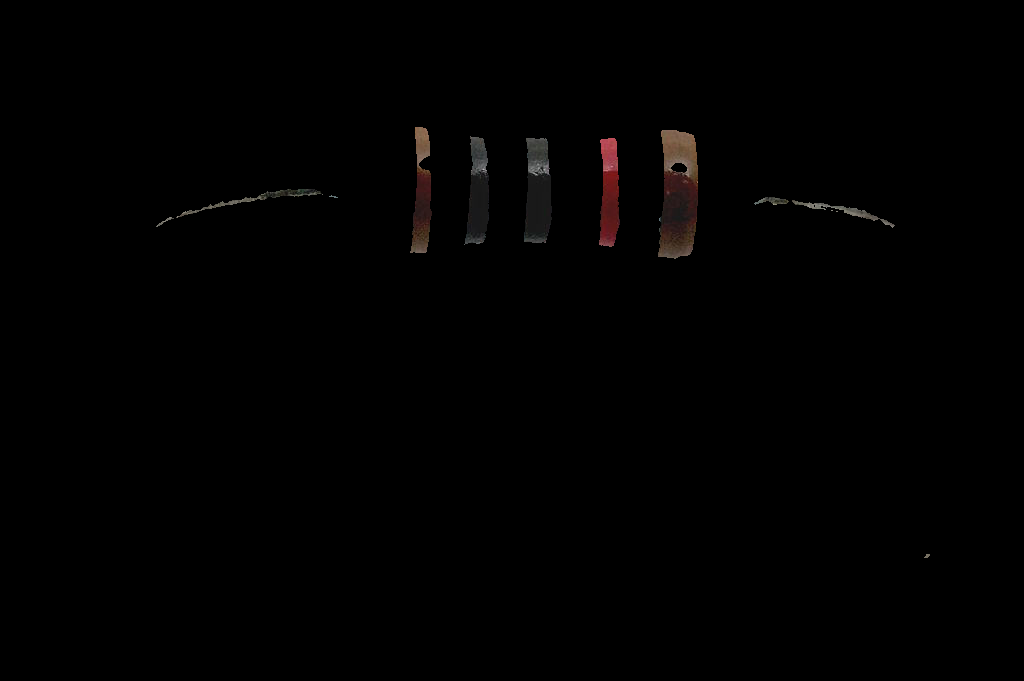

-1

In [20]:
# a mask is the same size as our image


masked = cv2.bitwise_and(rose, rose, mask=bw3)
cv2_imshow(masked)
cv2.waitKey(0)